# **TP3 - Data Preprocessing**

<b>Exploratory Data Analysis & Unsuperivsed Learning </b><br>
**Course: Dr. Sothea HAS** <br> 
**TP: Mr. Sreyvi UANN**

-------

**Objective**: This lab will demonstrate the critical role of data preprocessing. You will learn to identify and resolve common data quality issues (e.g., missing values, inconsistencies, outliers) to ensure the validity and reliability of your final analysis.


> **The `Jupyter Notebook` for this TP can be downloaded here: [TP3-Data-Preprocessing](https://hassothea.github.io/I5_EDA_ITC/TPs/TP3_Data_Preprocessing.ipynb)**.

-------

## **1. Missing Values**

[Cardiovascular diseases (CVDs)](https://www.who.int/health-topics/cardiovascular-diseases#tab=tab_1) are the leading cause of death globally, taking an estimated 17.9 million lives each year ([WHO](https://www.who.int/health-topics/cardiovascular-diseases#tab=tab_1)). CVDs are a group of disorders of the heart and blood vessels and include coronary heart disease, cerebrovascular disease, rheumatic heart disease and other conditions. More than four out of five CVD deaths are due to heart attacks and strokes, and one third of these deaths occur prematurely in people under 70 years of age. Heart failure is a common event caused by CVDs and this dataset contains 11 features that can be used to predict a possible heart disease.

The following `Heart Failure` dataset is obtained by combining 5 different heart disease datasets, consisting of 11 features and a target column indicating heart disease status of the patients. We will build a classification model to predict the heart status of the patients.

We will explore [Kaggle Heart Failure Dataset](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction). Load the dataset into the environment.

**a.** Import this data and name it `data`.

In [57]:
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")
data = pd.read_csv(path + '/heart.csv')
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


**b.** What's the dimension of the dataset? Check and modify if there are any columns with inappropriate data type.

In [58]:
data.shape

(918, 12)

In [59]:
data.dtypes.to_frame().T

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,int64,object,object,int64,int64,int64,object,int64,object,float64,object,int64


In [60]:
for col in ['FastingBS', 'HeartDisease']:
    data[col] = data[col].astype('category')
data.dtypes.to_frame().T

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,int64,object,object,int64,int64,category,object,int64,object,float64,object,category


**c.** Compute descriptive statistics of each column. 

- Do you observe anything strange? 

- Handle what seems to be the problem properly.

In [61]:
# Qualitative summary
qual_cols = data.select_dtypes(exclude='number').columns.to_list()
for col in qual_cols:
    print(data[col].value_counts(normalize=True), end='\n\n')

Sex
M    0.78976
F    0.21024
Name: proportion, dtype: float64

ChestPainType
ASY    0.540305
NAP    0.221133
ATA    0.188453
TA     0.050109
Name: proportion, dtype: float64

FastingBS
0    0.766885
1    0.233115
Name: proportion, dtype: float64

RestingECG
Normal    0.601307
LVH       0.204793
ST        0.193900
Name: proportion, dtype: float64

ExerciseAngina
N    0.595861
Y    0.404139
Name: proportion, dtype: float64

ST_Slope
Flat    0.501089
Up      0.430283
Down    0.068627
Name: proportion, dtype: float64

HeartDisease
1    0.553377
0    0.446623
Name: proportion, dtype: float64



In [62]:
# Quantitative
data.describe()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
count,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,136.809368,0.887364
std,9.432617,18.514154,109.384145,25.460334,1.066570
min,28.000000,0.000000,0.000000,60.000000,-2.600000
25%,47.000000,120.000000,173.250000,120.000000,0.000000
50%,54.000000,130.000000,223.000000,138.000000,0.600000
75%,60.000000,140.000000,267.000000,156.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


`RestingBP` and `Cholesterol` content zero values indicating invalid data. Therefore, they should be handled properly.

### Handle the problems

In [63]:
(data.RestingBP == 0).sum()/data.shape[0]

np.float64(0.0010893246187363835)

In [64]:
data.RestingBP[data.RestingBP == 0] = data.RestingBP[data.RestingBP > 0].median()

/var/folders/7g/054lbs0d6cj31wgldycfb31w0000gn/T/ipykernel_63952/2570680314.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data.RestingBP[data.RestingBP == 0] = data.RestingBP[data.RestingBP > 0].median()
/var/folders/7g/054lbs0d6cj31wg

In [65]:
data.describe()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
count,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.538126,198.799564,136.809368,0.887364
std,9.432617,17.990127,109.384145,25.460334,1.066570
min,28.000000,80.000000,0.000000,60.000000,-2.600000
25%,47.000000,120.000000,173.250000,120.000000,0.000000
50%,54.000000,130.000000,223.000000,138.000000,0.600000
75%,60.000000,140.000000,267.000000,156.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


In [66]:
(data.Cholesterol == 0).sum()/data.shape[0] * 100

np.float64(18.736383442265794)

There are around 19% zero valued data in `cholesterol` column. They have to be handled properly. Study the nature of those invalid/missing data. 

- `MCAR`: Missing Completely At Random it's randomly missing without affecting influenced from other data.
- `MAR`: Missing At Random it's missing based on some other data.
- `MNAR`: Missing Not At Random, the missingness occured due to the column itself.

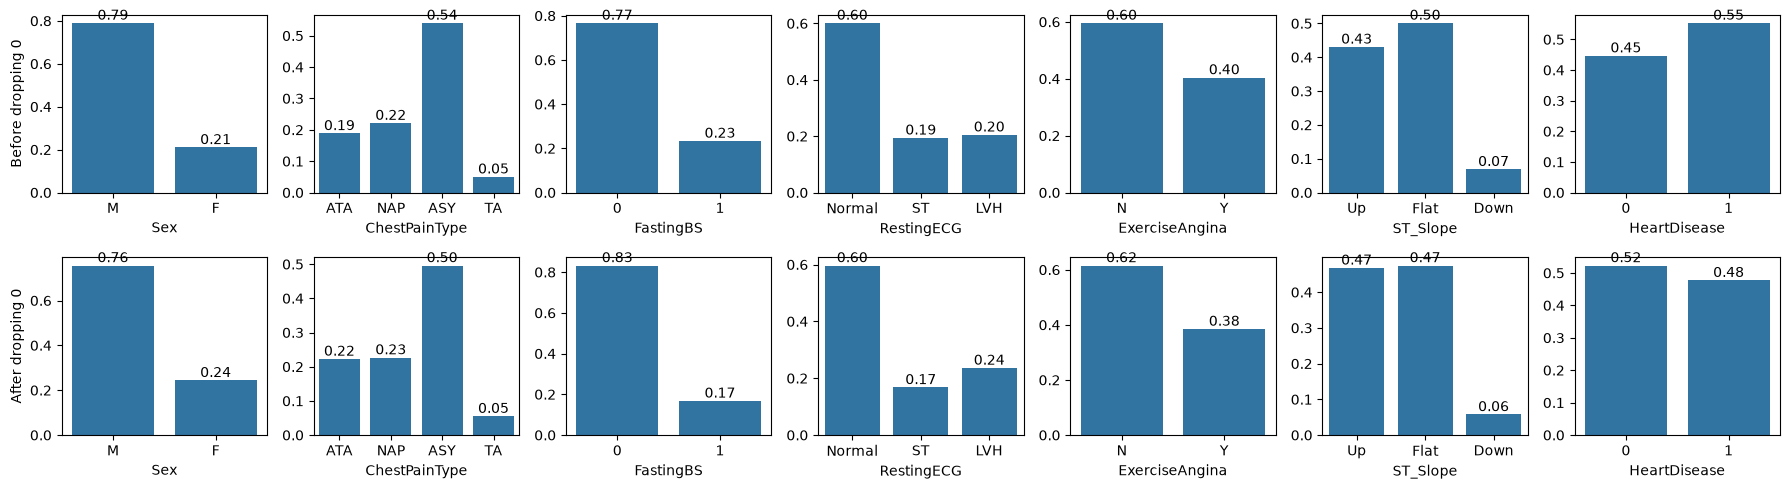

In [67]:
# Visualization

import seaborn as sns
import matplotlib.pyplot as plt
## Qualitative impact

fig, axes = plt.subplots(2, 7, figsize=(18, 5))

for i, col in enumerate(qual_cols):
    # Before dropping Cholesterol
    sns.countplot(
        data,
        x = col,
        stat='proportion',
        ax=axes[0, i]
    )
    # axes[0, i].set_title(col)
    axes[0, i].bar_label(axes[0, i].containers[0], fmt='%.2f')
    if i == 0:
        axes[0, i].set_ylabel("Before dropping 0")
    else:
        axes[0, i].set_ylabel("")
    # Remove Cholesterol 0
    sns.countplot(
        data.query("Cholesterol > 0"),
        x = col,
        stat='proportion',
        ax=axes[1, i]
    )
    # axes[1, i].set_title(col)
    axes[1, i].bar_label(axes[1, i].containers[0], fmt='%.2f')
    if i == 0:
        axes[1, i].set_ylabel("After dropping 0")
    else:
        axes[1, i].set_ylabel("")
plt.tight_layout()

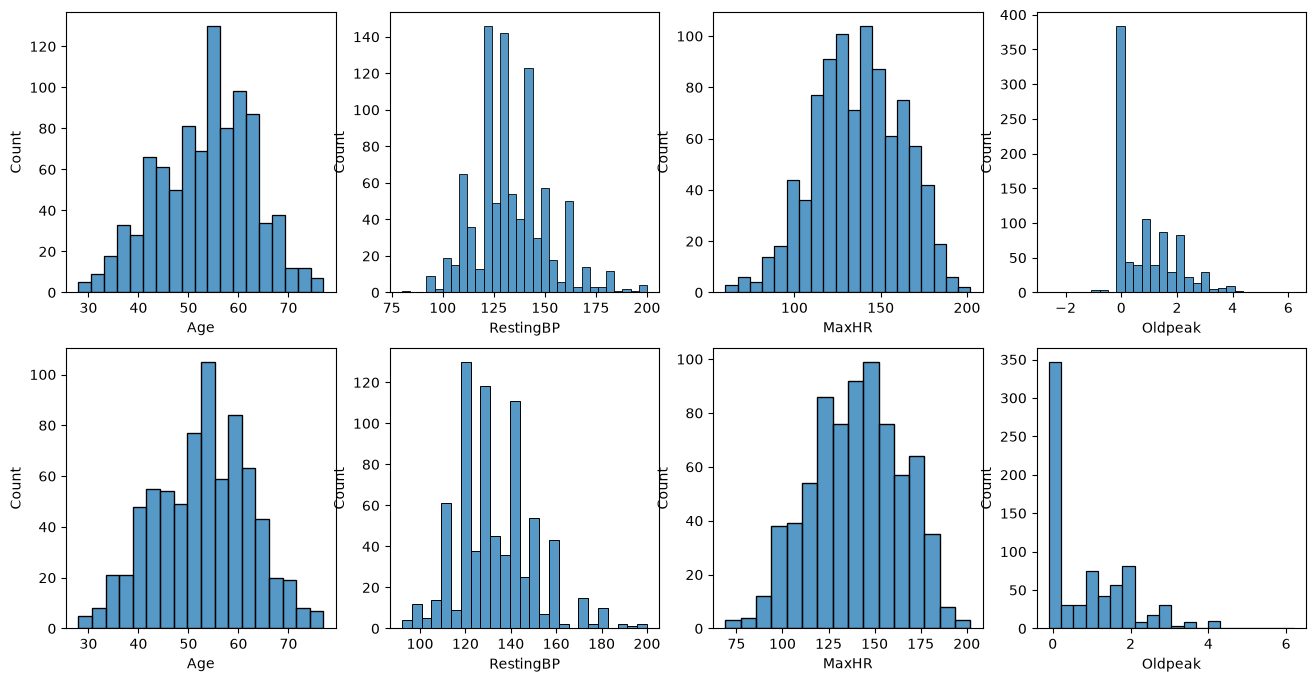

In [68]:
# Impact on quantitative columns
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
quan_cols = data.select_dtypes(include='number').columns.to_list()
i = 0
for col in quan_cols:
    if col != 'Cholesterol':
        sns.histplot(
            data, 
            x=col,
            ax=axes[0, i]
        )
        sns.histplot(
            data.query("Cholesterol > 0"), 
            x=col,
            ax=axes[1, i]
        )
        i += 1

- The zero values in `Cholesterol` columns are related to `HeartDisease` and `Oldpeak`. We may investigate the connection between those columns and `Cholesterol`.

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

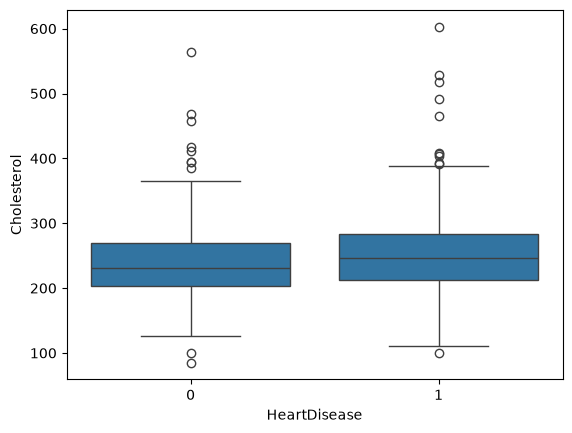

In [ ]:
# Relation between Cholesterol and HeartDisease.
data_no_zero = data.query("Cholesterol > 0")
sns.boxplot(
    data_no_zero,
    x = 'HeartDisease',
    y = "Cholesterol")

<Axes: xlabel='Oldpeak', ylabel='Cholesterol'>

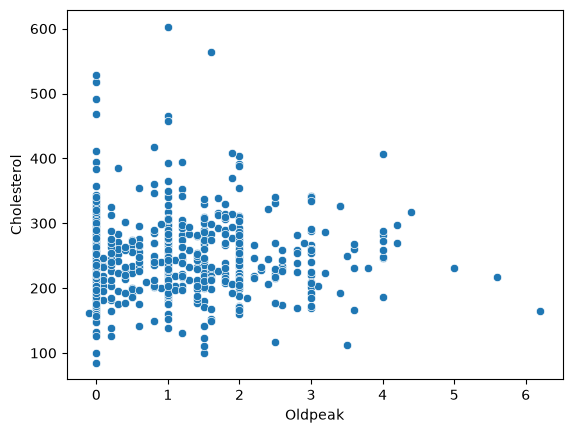

In [70]:
# Relation between Cholesterol and Oldpeak
sns.scatterplot(
    data_no_zero,
    x='Oldpeak',
    y='Cholesterol'
)

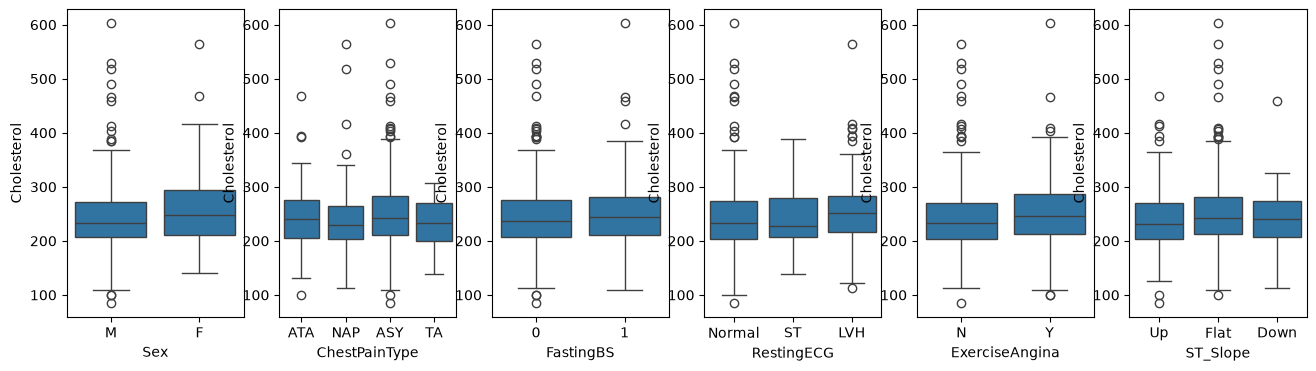

In [71]:
# Cholesterol vs qualitative coluns
_, axs = plt.subplots(1, 6, figsize=(16, 4))
i = 0
for col in qual_cols:
    if col != 'HeartDisease':
        sns.boxplot(
            data_no_zero,
            x=col,
            y="Cholesterol",
            ax=axs[i]
        )
        i+=1

In [87]:
corr = data[quan_cols].corr()
(corr.Cholesterol < -0.3).sum()

np.int64(0)

In [73]:
data[quan_cols].corr(method='spearman')

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
Age,1.000000,0.280073,-0.047156,-0.365025,0.298250
RestingBP,0.280073,1.000000,0.107127,-0.106225,0.177096
Cholesterol,-0.047156,0.107127,1.000000,0.183900,0.051723
MaxHR,-0.365025,-0.106225,0.183900,1.000000,-0.205113
Oldpeak,0.298250,0.177096,0.051723,-0.205113,1.000000


There seems to be no columns that are related singificantly with Cholesterol, therefore, we impute the invalid values with the median.

In [74]:
data.Cholesterol[data.Cholesterol == 0] = data.Cholesterol[data.Cholesterol > 0].median()
data.describe()

/var/folders/7g/054lbs0d6cj31wgldycfb31w0000gn/T/ipykernel_63952/3662259764.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data.Cholesterol[data.Cholesterol == 0] = data.Cholesterol[data.Cholesterol > 0].median()
/var/folders/7g/054lbs0

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
count,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.538126,243.204793,136.809368,0.887364
std,9.432617,17.990127,53.401297,25.460334,1.066570
min,28.000000,80.000000,85.000000,60.000000,-2.600000
25%,47.000000,120.000000,214.000000,120.000000,0.000000
50%,54.000000,130.000000,237.000000,138.000000,0.600000
75%,60.000000,140.000000,267.000000,156.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


**d.** Are there any potential outliers? Take a note for later improvement in your analysis. 

- Are there any duplicated observations? Handle them properly.

In [75]:
# To do

## 2. Outliers & high leverage data

In an unsupervised framework, outliers are data points that significantly deviate from the majority of observations. In a supervised framework, inputs with extreme values (but not their target) are known as high leverage points. Both outliers and high leverage points may obscure (but not always) the true underlying patterns in the data, often complicating analysis and leading to potential inaccuracies. We will start hunting outliers and high leverage points using [`Abalone` dataset](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset).

**a.** Download and import the dataset.

In [76]:
# To do

**b.** Compute and visualize both correaltion matrices. Provide your first impression on the correlation matrices.

In [77]:
# To do

**c.** Study the relation between `Type` and the most interesting variable (target) `Rings`.

In [78]:
# To do

**d.** Insepct outliers and high leverage data points (considering `Rings` as the target) in the dataset. You might be interested in the following interesting lessons from STAT 501:
- [Using Leverages to Help Identify Extreme x Values, STAT 501](https://online.stat.psu.edu/stat501/lesson/11/11.2)
- [Identifying Outliers (Unusual y Values), STAT 501](https://online.stat.psu.edu/stat501/lesson/11/11.3)

In [79]:
# To do

**e.** Once again, study the correlation matrices of the data after removing outliers and high leverage data points. Conclude.

In [80]:
# To do


# Further Readings

- [Outliers & high leverage observations](https://online.stat.psu.edu/stat501/lesson/11/11.1#:~:text=A%20data%20point%20has%20high,is%20particularly%20high%20or%20low.)
- [Using Leverages to Help Identify Extreme x Values, STAT 501](https://online.stat.psu.edu/stat501/lesson/11/11.2)
- [Identifying Outliers (Unusual y Values), STAT 501](https://online.stat.psu.edu/stat501/lesson/11/11.3)
- [Missing data: types, explanation, Imputation](https://www.scribbr.com/statistics/missing-data/)
- [Kaggle: Abalone dataset](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset)
- [Chapet 3, section 3.3.3 of The Introduction to Statistical Learning](https://www.stat.berkeley.edu/~rabbee/s154/ISLR_First_Printing.pdf)